# Linear Regression in PyTorch: how a machine learns a straight line, and when to trust it

**The question:** fitting a line through dots is the simplest model in machine learning, and also the one that teaches the most. Behind it hide questions that matter for every bigger network: *does the machine find the right answer, how fast, what can break it, and how sure should we be of what it learned?*

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. The maths by hand (gradients, checked against PyTorch)
4. Audit the data
5. Hypotheses and why we chose each test
6. H1: is there a real slope, and does PyTorch find it?
7. H2: how big can the learning rate be?
8. H3: does the scale of the inputs matter?
9. H4: can we trust the "95%" interval?
10. H5: what happens when some data is wrong?
11. Takeaways
12. Limitations

**Run it:** `uv run jupyter lab DL/linear-regression-pytorch/linear_regression_pytorch.ipynb`, or *Run All* in any Jupyter. The data is generated in the notebook, so there is nothing to download, and it takes about a minute on a CPU.

## 1. 💡 The simple analogy

Imagine a **ball rolling down a hill** to find the lowest point.

- The **line** you draw through the dots has two knobs: how steep it is (the *slope*) and where it starts (the *intercept*).
- The **loss** is the hill: the higher the line's average miss (squared) from the dots, the higher up the hill you are. The best line sits at the very bottom.
- **Gradient descent** is the ball: at every step, feel which way is downhill and roll a little that way.
- The **learning rate** is the size of each roll. Tiny rolls take forever. Rolls that are too big overshoot the valley and bounce higher and higher until the ball flies off the map.
- **Outliers** are a few dots someone placed in the wrong spot. A line that cares a lot about big misses (squared loss) gets yanked towards them; a line with a gentler rule for big misses (Huber loss) mostly ignores them.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the noise level and the number of simulations keeps the notebook reproducible and avoids "magic numbers". Because we generate the data ourselves with a **known true slope**, we can check every method against the truth, something real data never allows.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import torch
import torch.nn.functional as F
from scipy import stats
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.proportion import proportion_confint
from torch import nn

OUT_DIR = Path("outputs")
SEED = 365
N_SAMPLES = 200
NOISE_SD = 25.0
N_BOOTSTRAP = 5_000
N_COVERAGE_RUNS = 2_000
N_OUTLIER_RUNS = 200
CONVERGED_WITHIN = 0.01  # "converged" = training loss within 1% of the best possible
MAX_STEPS = 50_000
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if p < 1e-300 else f"{p:.1e}"

## 3. The maths by hand, checked against PyTorch

*What:* a line is $\hat{y} = w x + b$, and its loss is the mean squared error $L = \frac{1}{n}\sum (\hat{y}_i - y_i)^2$. "Which way is downhill?" is the **gradient**, found with a little calculus:

$$\frac{\partial L}{\partial w} = \frac{2}{n}\sum (\hat{y}_i - y_i)\,x_i \qquad \frac{\partial L}{\partial b} = \frac{2}{n}\sum (\hat{y}_i - y_i)$$

PyTorch's `loss.backward()` computes these automatically (**autograd**). *Why write them by hand?* To see there is no magic. We check our formulas against autograd on a toy example; an `assert` stops the notebook if they ever disagree.

In [2]:
def mse_gradient(x: np.ndarray, y: np.ndarray, w: float, b: float) -> tuple[float, float]:
    """Gradient of the mean squared error of the line ``w * x + b``, derived by hand.

    L = mean((w x + b - y)^2), so dL/dw = 2 mean((pred - y) x) and dL/db = 2 mean(pred - y).

    Args:
        x: Inputs, shape (n,).
        y: Targets, shape (n,).
        w: Current slope.
        b: Current intercept.

    Returns:
        The pair (dL/dw, dL/db).
    """
    error = w * x + b - y
    return float(2 * (error * x).mean()), float(2 * error.mean())


toy_x, toy_y = np.array([1.0, 2.0, 3.0]), np.array([2.0, 4.0, 5.0])
tx, ty = torch.tensor(toy_x), torch.tensor(toy_y)
tw = torch.tensor(0.5, dtype=torch.float64, requires_grad=True)
tb = torch.tensor(0.1, dtype=torch.float64, requires_grad=True)
F.mse_loss(tw * tx + tb, ty).backward()
mine = mse_gradient(toy_x, toy_y, 0.5, 0.1)
print(f"My gradient:       dL/dw = {mine[0]:.6f}, dL/db = {mine[1]:.6f}")
print(f"PyTorch autograd:  dL/dw = {tw.grad.item():.6f}, dL/db = {tb.grad.item():.6f}")
assert np.allclose(mine, (tw.grad.item(), tb.grad.item()))

My gradient:       dL/dw = -11.600000, dL/db = -5.133333
PyTorch autograd:  dL/dw = -11.600000, dL/db = -5.133333


## 4. Audit the data first

*What:* generate 200 points from a straight line plus random noise, and see what a perfect method could possibly achieve. *Why:* the noise sets a floor. Even the true line cannot beat it, so we need to know what that floor is before judging any model.

> **Problems in the legacy notebook this replaces:** it fitted one model once, with a hand-picked learning rate (0.033) and number of epochs (140), and **never compared the result with the exact answer**, never asked how uncertain the slope is, and never checked that the line was a reasonable description. It also used the old `super(Class, self)` style and had no explanation of why the numbers were chosen.

In [3]:
x_np, y_np, true_coef = make_regression(N_SAMPLES, 1, noise=NOISE_SD, random_state=SEED, coef=True)
x_flat = x_np[:, 0]
TRUE_SLOPE = float(true_coef)
design = sm.add_constant(x_flat)
ols = sm.OLS(y_np, design).fit()
ols_b, ols_w = ols.params
best_loss = float(np.mean(ols.resid**2))

print(f"{N_SAMPLES} points; true slope {TRUE_SLOPE:.2f}, true intercept 0, noise sd {NOISE_SD:.0f}")
print(f"x: mean {x_flat.mean():.2f}, sd {x_flat.std():.2f}")
print(f"y: mean {y_np.mean():.1f}, sd {y_np.std():.1f}")
print(f"A flat line at the mean of y has MSE {y_np.var():.0f}")
print(f"The best straight line has MSE {best_loss:.0f}")
print(f"Closed form: slope {ols_w:.3f}, intercept {ols_b:.3f}, R^2 {ols.rsquared:.3f}")

200 points; true slope 74.81, true intercept 0, noise sd 25
x: mean -0.01, sd 0.97
y: mean 1.2, sd 77.9
A flat line at the mean of y has MSE 6074
The best straight line has MSE 704
Closed form: slope 75.402, intercept 1.942, R^2 0.884


**How to read this:**

- The data is **200 points** with a **true slope of 74.81** and a noise standard deviation of **25**. Because the noise is 25, the best any line can do is an average squared miss of about 25² = 625; our line's training MSE is **704**, a little higher because it was fitted to 200 noisy points.
- A flat line at the average of y would miss by **6,074** (squared), so the straight line explains **88.4%** of the variation ($R^2 = 0.884$).
- The **closed-form least-squares answer** (the exact bottom of the hill, found with algebra, no rolling) is slope **75.402**, intercept **1.942**. We will treat this as the target for gradient descent.

## 5. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Is there a real relationship, and does PyTorch's SGD recover it? | Slope = 0 | Slope ≠ 0 | t-test on the slope, t and bootstrap intervals, 5-fold CV error vs the noise floor |
| H2 | Is there a learning rate above which gradient descent fails, and can we predict it? | Any learning rate works if you wait | A hard ceiling exists, set by the curvature of the loss | Sweep of learning rates, compared with 2 / (largest curvature) |
| H3 | Does rescaling the input change how fast gradient descent converges? | Steps to converge are the same | Raw units are far slower | Condition number and steps to converge on the same data in three units |
| H4 | Does a "95%" interval catch the truth 95% of the time? | Coverage = 95% | Coverage < 95% when the noise is uneven | 2,000 simulations, Wilson intervals on the coverage; classical vs HC3 robust errors |
| H5 | Is squared loss as accurate as Huber loss when some targets are wrong? | Equal slope error | Huber has smaller error | 200 paired data sets, Wilcoxon signed-rank, bootstrap CI of the difference |

*Why these tests?* The t-test is the textbook test for a regression slope, but it leans on assumptions (equal spread, roughly normal residuals), so H4 *tests the test* by simulation. The Wilcoxon signed-rank test is used for H5 because errors are skewed and the data sets are paired (both losses see the same data).

## 6. H1: is there a real slope, and does PyTorch find it?

*What:* train the original notebook's model (`nn.Linear(1, 1)`, plain SGD, learning rate 0.033, 140 epochs) and compare it with the exact answer. Then ask the statistical question: *could a slope this steep appear by chance if there were really no relationship?* We answer with a t-test, a 95% t-interval and a bootstrap interval (re-fit the line to 5,000 resamples of the data, drawn with replacement). Finally, we check how well the line predicts **unseen** points with 5-fold cross-validation and compare the error to the noise floor of 25.

*Why cross-validation?* The training loss only says how well the line fits the points it has seen; held-out error says how it will do on new ones.

In [4]:
def train_torch_line(
    x: np.ndarray, y: np.ndarray, lr: float, n_epochs: int, seed: int = SEED
) -> tuple[nn.Module, list[float]]:
    """Trains ``nn.Linear(1, 1)`` with full-batch SGD, as the original notebook did.

    Args:
        x: Inputs, shape (n,).
        y: Targets, shape (n,).
        lr: Learning rate.
        n_epochs: Number of full passes (here, one step per pass).
        seed: Seed for the random starting weights.

    Returns:
        The trained model and the loss recorded before each step.
    """
    torch.manual_seed(seed)
    inputs = torch.tensor(x, dtype=torch.float32).view(-1, 1)
    targets = torch.tensor(y, dtype=torch.float32).view(-1, 1)
    model = nn.Linear(1, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    history = []
    for _ in range(n_epochs):
        loss = F.mse_loss(model(inputs), targets)
        history.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model, history


model, _ = train_torch_line(x_flat, y_np, lr=0.033, n_epochs=140)
torch_w, torch_b = model.weight.item(), model.bias.item()
print(f"PyTorch (lr 0.033, 140 epochs): slope {torch_w:.3f}, intercept {torch_b:.3f}")
print(f"Closed form:                    slope {ols_w:.3f}, intercept {ols_b:.3f}")

slope_ci = ols.conf_int()[1]
rows = np.arange(N_SAMPLES)
boot = np.empty(N_BOOTSTRAP)
for i in range(N_BOOTSTRAP):
    pick = rng.choice(rows, N_SAMPLES)
    boot[i] = np.polyfit(x_flat[pick], y_np[pick], 1)[0]
boot_ci = np.percentile(boot, [2.5, 97.5])
print(f"\nH0: slope = 0.  t = {ols.tvalues[1]:.1f}, p = {fmt_p(ols.pvalues[1])}")
print(
    f"Slope {ols_w:.2f}: 95% t-interval {slope_ci[0]:.2f} to {slope_ci[1]:.2f}; "
    f"bootstrap interval {boot_ci[0]:.2f} to {boot_ci[1]:.2f}"
)
print(
    f"Does the interval contain the true slope {TRUE_SLOPE:.2f}? "
    f"{slope_ci[0] <= TRUE_SLOPE <= slope_ci[1]}"
)

cv_pred = cross_val_predict(
    LinearRegression(), x_np, y_np, cv=KFold(5, shuffle=True, random_state=SEED)
)
sq_err = (cv_pred - y_np) ** 2
cv_rmse = float(np.sqrt(sq_err.mean()))
boot_rmse = np.sqrt([sq_err[rng.choice(rows, N_SAMPLES)].mean() for _ in range(N_BOOTSTRAP)])
rmse_ci = np.percentile(boot_rmse, [2.5, 97.5])
print(
    f"\nHeld-out RMSE (5-fold CV): {cv_rmse:.1f} (95% bootstrap CI {rmse_ci[0]:.1f} to "
    f"{rmse_ci[1]:.1f}); the unavoidable noise is {NOISE_SD:.0f}"
)

PyTorch (lr 0.033, 140 epochs): slope 75.393, intercept 1.941
Closed form:                    slope 75.402, intercept 1.942



H0: slope = 0.  t = 38.9, p = 1.4e-94
Slope 75.40: 95% t-interval 71.58 to 79.23; bootstrap interval 71.56 to 79.10
Does the interval contain the true slope 74.81? True

Held-out RMSE (5-fold CV): 26.6 (95% bootstrap CI 24.1 to 29.2); the unavoidable noise is 25


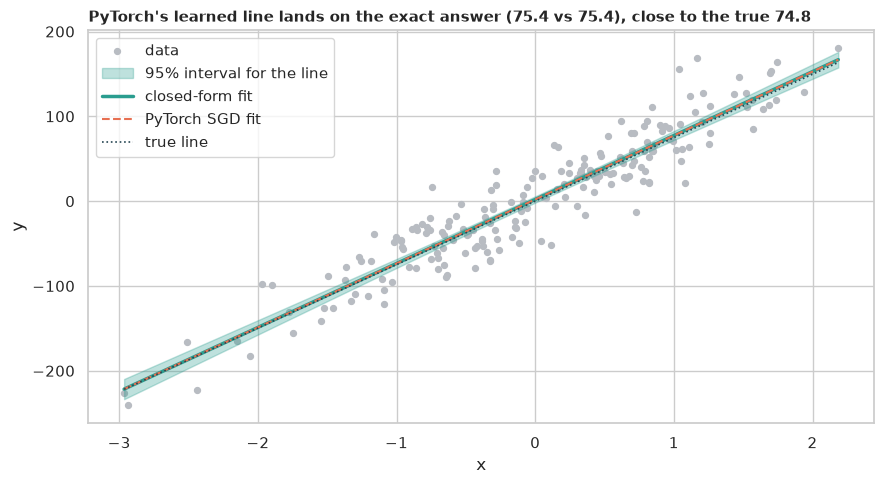

In [5]:
grid = np.linspace(x_flat.min(), x_flat.max(), 200)
band = ols.get_prediction(sm.add_constant(grid)).summary_frame(alpha=0.05)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(x_flat, y_np, color=GREY, s=18, label="data", zorder=1)
ax.fill_between(
    grid,
    band["mean_ci_lower"],
    band["mean_ci_upper"],
    color=TEAL,
    alpha=0.3,
    label="95% interval for the line",
    zorder=2,
)
ax.plot(grid, ols_b + ols_w * grid, color=TEAL, lw=2.5, label="closed-form fit", zorder=3)
ax.plot(
    grid, torch_b + torch_w * grid, color=ORANGE, lw=1.5, ls="--", label="PyTorch SGD fit", zorder=4
)
ax.plot(grid, TRUE_SLOPE * grid, color=NAVY, lw=1.2, ls=":", label="true line", zorder=4)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(
    f"PyTorch's learned line lands on the exact answer ({torch_w:.1f} vs {ols_w:.1f}), "
    f"close to the true {TRUE_SLOPE:.1f}",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "01_fit.png", dpi=150)
plt.show()

**How to read this:**

- **PyTorch matches the exact answer.** SGD gives slope **75.393** and intercept **1.941** against the closed-form **75.402** and **1.942**: the same line to within a hundredth. On the plot the dashed orange and solid teal lines are on top of each other.
- **The slope is real.** The t statistic is **38.9** with $p = 1.4\times10^{-94}$, so **we reject H₀**. The 95% t-interval is **71.58 to 79.23** and the bootstrap interval is **71.56 to 79.10**: nearly identical, and both contain the true slope of **74.81**.
- **Held-out error is close to the floor.** The 5-fold CV RMSE is **26.6** (95% bootstrap CI **24.1 to 29.2**). The unavoidable noise is 25, which sits inside the interval: the model is about as good as any line could be on this data.
- The shaded band shows that the *line* is known fairly precisely, but individual points still scatter around it by about 25; they are different questions.

## 7. H2: how big can the learning rate be?

*What:* run plain gradient descent (the same as `torch.optim.SGD` for this full-batch problem, written in NumPy so we can run many settings quickly) at eight learning rates, and count the steps until the training loss is within **1% of the best possible loss**. We call a run "blown up" if the loss explodes.

*Theory to test:* the loss is a bowl, and its steepest curvature is the largest eigenvalue $\lambda_{\max}$ of $\frac{2}{n}X^\top X$. Gradient descent overshoots whenever the learning rate exceeds $2/\lambda_{\max}$, so that should be the hard ceiling.

In [6]:
def gradient_descent(
    design_matrix: np.ndarray, y: np.ndarray, lr: float, max_steps: int = MAX_STEPS
) -> tuple[list[float], int | None]:
    """Full-batch gradient descent on the mean squared error, until "close enough".

    Args:
        design_matrix: Inputs with a leading column of ones, shape (n, 2).
        y: Targets, shape (n,).
        lr: Learning rate.
        max_steps: Give up after this many steps.

    Returns:
        The loss history and the step at which the loss came within ``CONVERGED_WITHIN`` of the
        best possible (``None`` if it never did: too slow, or it blew up).
    """
    best = float(
        np.mean((y - design_matrix @ np.linalg.lstsq(design_matrix, y, rcond=None)[0]) ** 2)
    )
    weights = np.zeros(design_matrix.shape[1])
    history = []
    for step in range(max_steps):
        residual = design_matrix @ weights - y
        loss = float(np.mean(residual**2))
        history.append(loss)
        if loss <= best * (1 + CONVERGED_WITHIN):
            return history, step
        if not np.isfinite(loss) or loss > 1e12:
            return history, None
        weights = weights - lr * 2 * design_matrix.T @ residual / len(y)
    return history, None


def stability_limit(design_matrix: np.ndarray) -> float:
    """Largest learning rate gradient descent can survive: 2 / (top curvature of the loss).

    Args:
        design_matrix: Inputs with a leading column of ones, shape (n, 2).

    Returns:
        The critical learning rate.
    """
    curvature = np.linalg.eigvalsh(2 * design_matrix.T @ design_matrix / len(design_matrix))
    return float(2 / curvature.max())


X_raw = np.column_stack([np.ones(N_SAMPLES), x_flat])
lr_limit = stability_limit(X_raw)
LRS = [0.001, 0.01, 0.033, 0.1, 0.5, 0.9, 1.0, 1.05]
sweep = {lr: gradient_descent(X_raw, y_np, lr) for lr in LRS}
sweep_table = pd.DataFrame(
    {
        "learning rate": LRS,
        "x the stability limit": [lr / lr_limit for lr in LRS],
        "steps to converge": [s[1] if s[1] is not None else float("nan") for s in sweep.values()],
        "outcome": ["converged" if s[1] is not None else "blew up" for s in sweep.values()],
    }
).set_index("learning rate")
print(f"Stability limit from the curvature of the loss: {lr_limit:.3f}")
print(sweep_table.round(2).to_string())
print(f"\nOriginal notebook (lr 0.033, 140 epochs): converged at step {sweep[0.033][1]}")

Stability limit from the curvature of the loss: 0.999
               x the stability limit  steps to converge    outcome
learning rate                                                     
0.001                           0.00             1757.0  converged
0.010                           0.01              175.0  converged
0.033                           0.03               52.0  converged
0.100                           0.10               16.0  converged
0.500                           0.50                2.0  converged
0.900                           0.90               10.0  converged
1.000                           1.00                NaN    blew up
1.050                           1.05                NaN    blew up

Original notebook (lr 0.033, 140 epochs): converged at step 52


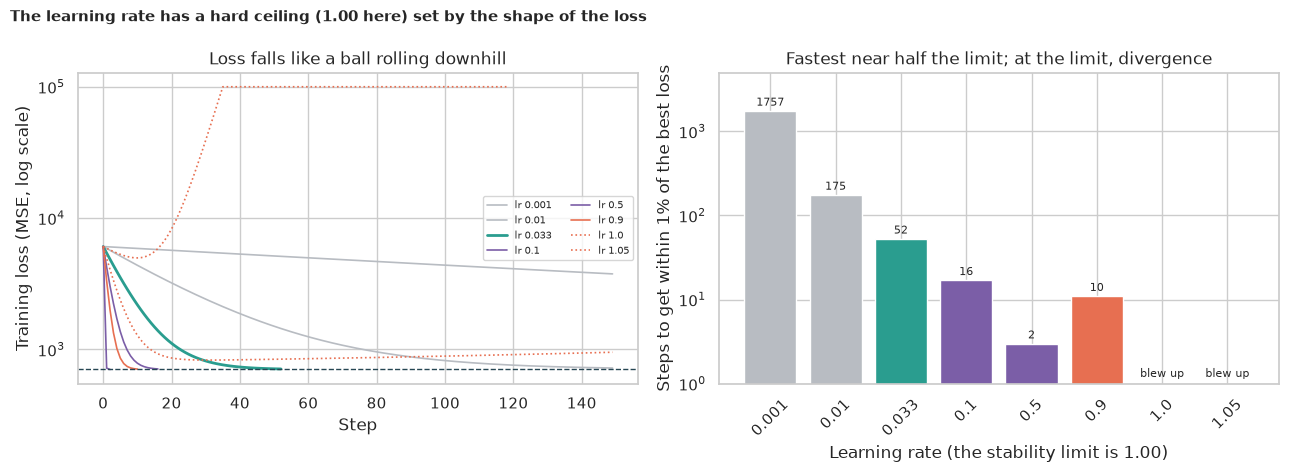

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colors = [GREY, GREY, TEAL, PURPLE, PURPLE, ORANGE, ORANGE, ORANGE]
for (lr, (history, steps)), color in zip(sweep.items(), colors, strict=True):
    shown = np.clip(history[:150], None, 1e5)
    axes[0].plot(
        shown,
        label=f"lr {lr}",
        lw=2 if lr == 0.033 else 1.2,
        color=color,
        ls="-" if steps is not None else ":",
    )
axes[0].axhline(best_loss, color=NAVY, ls="--", lw=1)
axes[0].set_yscale("log")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Training loss (MSE, log scale)")
axes[0].set_title("Loss falls like a ball rolling downhill")
axes[0].legend(fontsize=7, ncol=2)

steps_plot = [s[1] if s[1] is not None else np.nan for s in sweep.values()]
axes[1].bar(range(len(LRS)), [v + 1 if v == v else 0 for v in steps_plot], color=colors)
for i, steps in enumerate(steps_plot):
    axes[1].text(
        i,
        (steps + 1) * 1.15 if steps == steps else 1.2,
        f"{int(steps)}" if steps == steps else "blew up",
        ha="center",
        fontsize=8,
    )
axes[1].set_xticks(range(len(LRS)), [str(lr) for lr in LRS], rotation=45)
axes[1].set_yscale("log")
axes[1].set_ylim(1, 5000)
axes[1].set_xlabel(f"Learning rate (the stability limit is {lr_limit:.2f})")
axes[1].set_ylabel("Steps to get within 1% of the best loss")
axes[1].set_title("Fastest near half the limit; at the limit, divergence")
fig.suptitle(
    f"The learning rate has a hard ceiling ({lr_limit:.2f} here) set by the shape of the loss",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_learning_rates.png", dpi=150)
plt.show()

**How to read this:**

- **The ceiling is real and we predicted it.** The curvature formula gives a stability limit of **0.999**. Learning rate **0.9** (90% of the limit) converges in **10 steps**; **1.0** and **1.05** blow up. So **we reject H₀**: waiting longer does not rescue a learning rate above the limit.
- **Below the ceiling, bigger is faster:** **1,757 steps** at 0.001, **175** at 0.01, **16** at 0.1 and just **2** at 0.5 (half the limit). Note that 0.9 is slower than 0.5 (10 steps vs 2): close to the limit the ball starts to bounce from side to side.
- **The original notebook's choice (0.033)** needed **52 steps**, so its 140 epochs were more than enough, though a rate about 15 times larger would have finished in a couple of steps. Nobody could know that without the analysis above.
- In the left plot, the dotted orange lines are the runs that failed: at 1.0 the loss climbs and gets stuck at the clip at $10^5$ (the real value keeps growing), and at 1.05 it explodes.

## 8. H3: does the scale of the inputs matter?

*What:* the same relationship, with the input expressed in different units: **raw** values around 300 with a spread of 50 (like house sizes in square feet), **centred** (mean subtracted) and **standardised** (mean 0, spread 1). We give each its best treatment: a learning rate of 90% of *its own* stability limit, up to 50,000 steps.

*Why it should matter:* when x sits far from zero, the slope and the intercept are tangled together: nudging either one changes the line in nearly the same way. The loss becomes a long, thin, tilted valley. The **condition number** (steepest curvature divided by gentlest) measures how thin; large means a slow crawl along the valley floor.

In [8]:
x_raw_units = x_flat * 50 + 300  # the same relationship, but in "large" units (like square feet)
x_centred = x_raw_units - x_raw_units.mean()
x_standard = x_centred / x_raw_units.std()
variants = {
    "raw units (x around 300)": x_raw_units,
    "centred (mean 0, sd 50)": x_centred,
    "standardised (mean 0, sd 1)": x_standard,
}
scaling_rows = []
histories = {}
for name, values in variants.items():
    design_v = np.column_stack([np.ones(N_SAMPLES), values])
    limit = stability_limit(design_v)
    curvature = np.linalg.eigvalsh(2 * design_v.T @ design_v / N_SAMPLES)
    history, steps = gradient_descent(design_v, y_np, 0.9 * limit)
    histories[name] = history
    scaling_rows.append(
        {
            "inputs": name,
            "condition number": curvature.max() / curvature.min(),
            "stability limit": limit,
            "steps to converge (at 0.9 x limit)": steps if steps is not None else float("nan"),
            "loss when stopped": history[-1],
        }
    )
scaling = pd.DataFrame(scaling_rows).set_index("inputs")
pd.options.display.float_format = "{:,.4g}".format
print(scaling.to_string())
print(f"\nBest possible loss: {best_loss:.1f}")
pd.reset_option("display.float_format")

                             condition number  stability limit  steps to converge (at 0.9 x limit)  loss when stopped
inputs                                                                                                               
raw units (x around 300)            3.592e+06        1.086e-05                                 NaN              5,653
centred (mean 0, sd 50)                 2,361        0.0004235                                  16                710
standardised (mean 0, sd 1)                 1                1                                  15              710.9

Best possible loss: 704.2


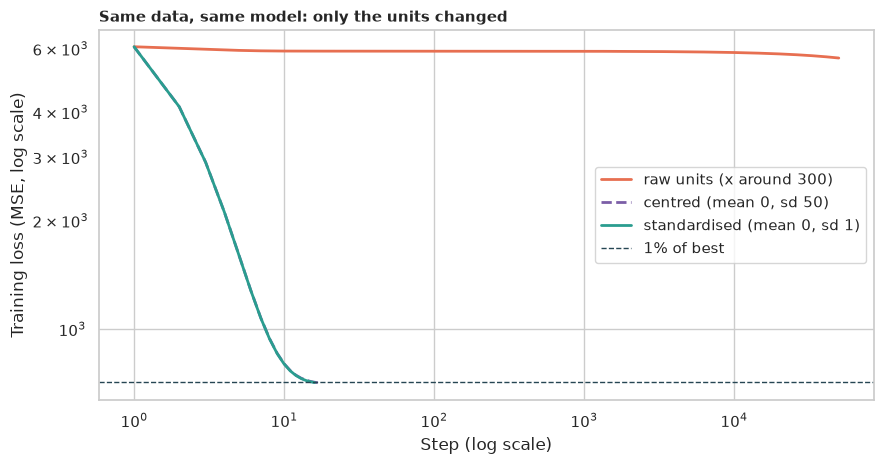

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for (name, history), color in zip(histories.items(), [ORANGE, PURPLE, TEAL], strict=True):
    ax.plot(
        np.arange(1, len(history) + 1),
        history,
        label=name,
        color=color,
        lw=2,
        ls="--" if "centred" in name else "-",
    )
ax.axhline(best_loss * (1 + CONVERGED_WITHIN), color=NAVY, ls="--", lw=1, label="1% of best")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Step (log scale)")
ax.set_ylabel("Training loss (MSE, log scale)")
ax.set_title(
    "Same data, same model: only the units changed", loc="left", fontweight="bold", fontsize=11
)
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "03_scaling.png", dpi=150)
plt.show()

**How to read this:**

- **Raw units are a disaster.** The condition number is **3.6 million**, the stability limit shrinks to **0.0000109**, and after **50,000 steps the loss is still 5,653** (the best possible is 704.2). It never converged. **We reject H₀.**
- **Centring does most of the work here:** condition number **2,361**, converged in **16 steps**. Standardising goes to a condition number of **1** and converges in **15 steps**, with a stability limit of 1.0 so one learning rate suits every dataset.
- With a *single* input, centring and standardising behave almost alike (the two curves overlap on the plot). Standardising matters more with **many inputs in different units** (say, square feet next to number of bedrooms), where one learning rate must suit all of them at once, which is why it is the default step before training any neural network.
- The slow direction is still there for raw data: the loss drops fast at first, then crawls (the flat orange line).

## 9. H4: can we trust the "95%" interval?

*What:* the t-interval in H1 is only guaranteed to catch the truth 95% of the time if the noise has the **same spread everywhere** (and is roughly normal). Real data often fans out: bigger x, bigger scatter. We test the test by simulation: generate **2,000 fresh data sets** with a known slope, build a 95% interval on each, and count how often it catches the truth. We try constant noise and noise that grows with $|x|$, with the **classical** standard error and the **HC3 robust** standard error (which does not assume equal spread).

*Also:* diagnostic tests on our own data, Shapiro-Wilk (are the residuals normal?) and Breusch-Pagan (is their spread constant?).

In [10]:
def slope_covers(heteroscedastic: bool, robust: bool, n: int = N_SAMPLES) -> bool:
    """Simulates one data set with a known slope and asks: does the 95% interval catch it?

    Args:
        heteroscedastic: If true, the noise grows with ``|x|``; otherwise it is constant.
        robust: If true, use HC3 heteroscedasticity-robust standard errors.
        n: Number of points.

    Returns:
        Whether the interval contains the true slope.
    """
    xx = rng.normal(size=n)
    noise_sd = NOISE_SD * (0.3 + np.abs(xx)) if heteroscedastic else NOISE_SD
    yy = TRUE_SLOPE * xx + rng.normal(size=n) * noise_sd
    fit = sm.OLS(yy, sm.add_constant(xx)).fit(cov_type="HC3" if robust else "nonrobust")
    low, high = fit.conf_int()[1]
    return bool(low <= TRUE_SLOPE <= high)


coverage_rows = []
for label, het, robust in [
    ("constant noise, classical", False, False),
    ("constant noise, robust (HC3)", False, True),
    ("growing noise, classical", True, False),
    ("growing noise, robust (HC3)", True, True),
]:
    hits = sum(slope_covers(het, robust) for _ in range(N_COVERAGE_RUNS))
    low, high = proportion_confint(hits, N_COVERAGE_RUNS, method="wilson")
    coverage_rows.append(
        {"setting": label, "coverage": hits / N_COVERAGE_RUNS, "ci_low": low, "ci_high": high}
    )
coverage = pd.DataFrame(coverage_rows).set_index("setting")
print(f"Share of {N_COVERAGE_RUNS:,} simulated data sets whose 95% interval caught the true slope:")
print((coverage * 100).round(1).to_string())

resid = ols.resid
shapiro = stats.shapiro(resid)
bp_lm, bp_p, _, _ = het_breuschpagan(resid, design)
print(
    f"\nOn our data: Shapiro-Wilk (normal residuals) p = {shapiro.pvalue:.2f}; "
    f"Breusch-Pagan (equal spread) p = {bp_p:.2f}"
)

Share of 2,000 simulated data sets whose 95% interval caught the true slope:
                              coverage  ci_low  ci_high
setting                                                
constant noise, classical         94.4    93.4     95.4
constant noise, robust (HC3)      95.4    94.4     96.2
growing noise, classical          77.8    75.9     79.6
growing noise, robust (HC3)       95.0    94.0     95.9

On our data: Shapiro-Wilk (normal residuals) p = 0.62; Breusch-Pagan (equal spread) p = 0.92


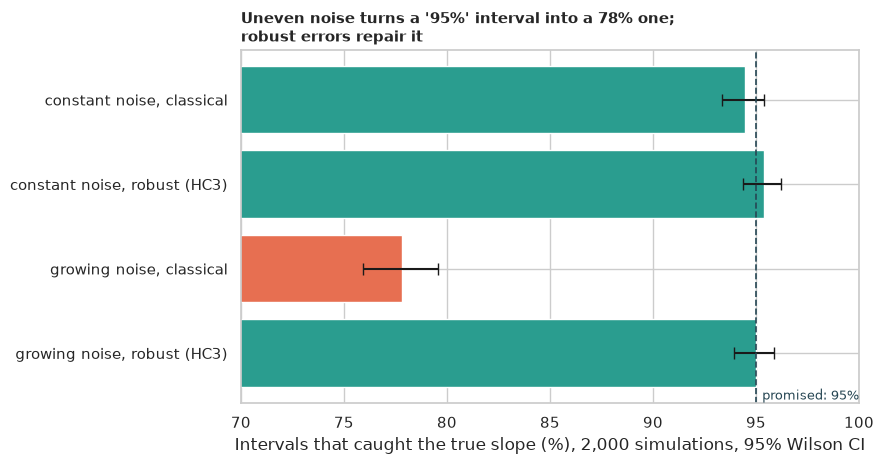

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.8))
bar_colors = [TEAL, TEAL, ORANGE, TEAL]
ypos = np.arange(len(coverage))
ax.barh(
    ypos,
    coverage["coverage"] * 100,
    color=bar_colors,
    xerr=[
        (coverage["coverage"] - coverage["ci_low"]) * 100,
        (coverage["ci_high"] - coverage["coverage"]) * 100,
    ],
    capsize=4,
)
ax.axvline(95, color=NAVY, ls="--", lw=1.2)
ax.text(95.3, len(coverage) - 0.45, "promised: 95%", color=NAVY, fontsize=9)
ax.set_yticks(ypos, coverage.index)
ax.invert_yaxis()
ax.set_xlim(70, 100)
ax.set_xlabel(
    f"Intervals that caught the true slope (%), {N_COVERAGE_RUNS:,} simulations, 95% Wilson CI"
)
worst = coverage["coverage"].min() * 100
ax.set_title(
    f"Uneven noise turns a '95%' interval into a {worst:.0f}% one;\nrobust errors repair it",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_coverage.png", dpi=150)
plt.show()

**How to read this:**

- **With constant noise the classical interval is honest:** **94.4%** (95% CI 93.4 to 95.4), consistent with the promised 95%. Robust errors give **95.4%**, so you lose nothing by using them.
- **With growing noise the classical interval fails:** it catches the truth only **77.8%** of the time (CI 75.9 to 79.6), far below 95%. A "95%" interval that is really a 78% one is dangerously over-confident. **We reject H₀** for the classical interval.
- **Robust (HC3) errors repair it:** **95.0%** (CI 94.0 to 95.9).
- **Our own data is fine:** Shapiro-Wilk $p = 0.62$ and Breusch-Pagan $p = 0.92$ show no evidence against normal residuals or constant spread, so the H1 interval can be trusted. (A failure to reject is not proof, but together with how the data was generated, it is reassuring.)
- The bars show Wilson intervals for the *simulated* coverage, so the small differences near 95% are within simulation noise.

## 10. H5: what happens when some data is wrong?

*What:* in **200 new data sets** with a known slope, we corrupt **10 of the 200 targets** (5%) by pushing them 400 units up or down, as with a broken sensor or typos. We fit each data set twice by gradient descent in PyTorch: with **squared loss** and with **Huber loss**, which is squared for small misses but grows only linearly for big ones (threshold set at 2× the noise, 50). All 400 lines train in one batched `backward()`, because each data set's loss is summed separately. The yardstick is how far each slope lands from the true one.

*Why a paired test?* Both losses see exactly the same 200 data sets, so we compare them set by set with the Wilcoxon signed-rank test, and put a bootstrap interval on the average difference.

In [12]:
OUTLIER_SHIFT = 400.0
N_OUTLIERS = 10
HUBER_DELTA = 2 * NOISE_SD


def contaminated_sets(n_sets: int) -> tuple[np.ndarray, np.ndarray]:
    """Builds data sets with a known slope where 5% of the targets are wildly wrong.

    Args:
        n_sets: How many independent data sets to build.

    Returns:
        Inputs and targets, each of shape (n_sets, N_SAMPLES).
    """
    xs = rng.normal(size=(n_sets, N_SAMPLES))
    ys = TRUE_SLOPE * xs + rng.normal(size=(n_sets, N_SAMPLES)) * NOISE_SD
    for i in range(n_sets):
        bad = rng.choice(N_SAMPLES, N_OUTLIERS, replace=False)
        ys[i, bad] += rng.choice([-1.0, 1.0], N_OUTLIERS) * OUTLIER_SHIFT
    return xs, ys


def fit_many_lines(
    xs: np.ndarray, ys: np.ndarray, loss_name: str, steps: int = 3_000
) -> np.ndarray:
    """Fits one line per row with SGD, all at once, using squared or Huber loss.

    Each row is its own independent problem; summing the per-row losses keeps their gradients
    separate, so one backward pass trains every line.

    Args:
        xs: Inputs, shape (n_sets, n).
        ys: Targets, shape (n_sets, n).
        loss_name: ``"mse"`` or ``"huber"``.
        steps: Number of gradient steps.

    Returns:
        The fitted slopes, shape (n_sets,).
    """
    x_t = torch.tensor(xs)
    y_t = torch.tensor(ys)
    slope = torch.zeros(len(xs), 1, dtype=torch.float64, requires_grad=True)
    intercept = torch.zeros(len(xs), 1, dtype=torch.float64, requires_grad=True)
    optimizer = torch.optim.SGD([slope, intercept], lr=0.1)
    for _ in range(steps):
        pred = slope * x_t + intercept
        if loss_name == "mse":
            per_set = ((pred - y_t) ** 2).mean(dim=1)
        else:
            per_set = F.huber_loss(pred, y_t, reduction="none", delta=HUBER_DELTA).mean(dim=1)
        optimizer.zero_grad()
        per_set.sum().backward()
        optimizer.step()
    return slope.detach().squeeze(1).numpy()


xs_bad, ys_bad = contaminated_sets(N_OUTLIER_RUNS)
slope_error = {
    name: np.abs(fit_many_lines(xs_bad, ys_bad, name) - TRUE_SLOPE) for name in ("mse", "huber")
}
paired = stats.wilcoxon(slope_error["mse"], slope_error["huber"])
diff = slope_error["mse"] - slope_error["huber"]
diff_ci = np.percentile(
    [rng.choice(diff, len(diff)).mean() for _ in range(N_BOOTSTRAP)], [2.5, 97.5]
)
wins = int((slope_error["huber"] < slope_error["mse"]).sum())
print(
    f"{N_OUTLIER_RUNS} data sets, each with {N_OUTLIERS} of {N_SAMPLES} targets pushed "
    f"+-{OUTLIER_SHIFT:.0f} away"
)
for name, label in [("mse", "squared loss"), ("huber", "Huber loss")]:
    err = slope_error[name]
    print(f"{label:>13}: mean absolute slope error {err.mean():.2f} (median {np.median(err):.2f})")
print(
    f"Squared minus Huber: {diff.mean():.2f} (95% bootstrap CI {diff_ci[0]:.2f} to "
    f"{diff_ci[1]:.2f}); Huber closer in {wins} of {N_OUTLIER_RUNS}; "
    f"Wilcoxon p = {fmt_p(paired.pvalue)}"
)

200 data sets, each with 10 of 200 targets pushed +-400 away
 squared loss: mean absolute slope error 4.71 (median 3.88)
   Huber loss: mean absolute slope error 1.53 (median 1.29)
Squared minus Huber: 3.19 (95% bootstrap CI 2.72 to 3.66); Huber closer in 162 of 200; Wilcoxon p = 2.3e-25


Typical data set (#115): squared-loss slope 78.7, Huber slope 73.5, true 74.8


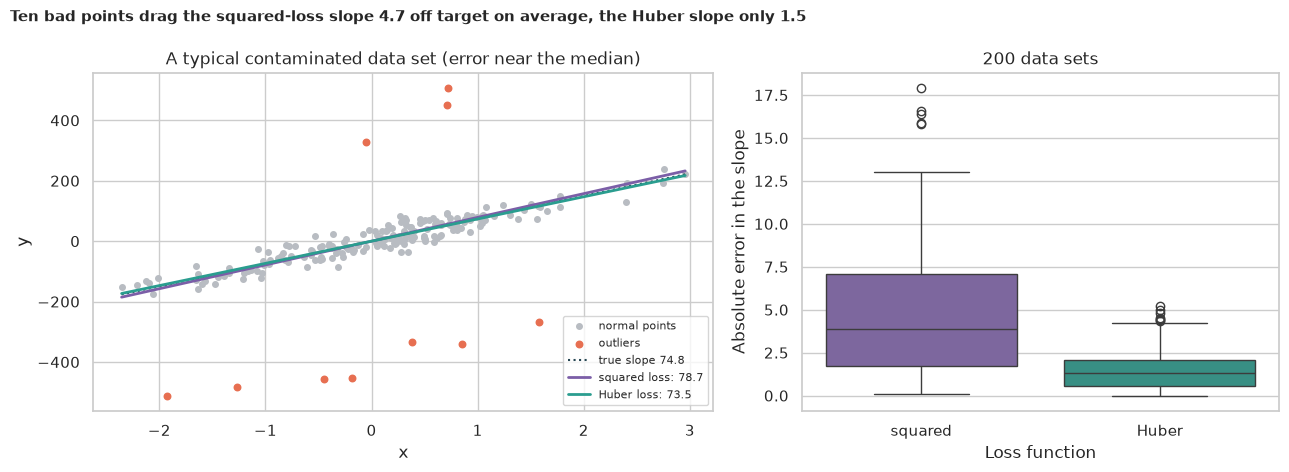

In [13]:
typical = int(
    np.argmin(
        np.abs(slope_error["mse"] - np.median(slope_error["mse"]))
        + np.abs(slope_error["huber"] - np.median(slope_error["huber"]))
    )
)
one_x, one_y = xs_bad[typical], ys_bad[typical]
mse_slope = fit_many_lines(xs_bad[typical : typical + 1], ys_bad[typical : typical + 1], "mse")[0]
huber_slope = fit_many_lines(xs_bad[typical : typical + 1], ys_bad[typical : typical + 1], "huber")[
    0
]
print(
    f"Typical data set (#{typical}): squared-loss slope {mse_slope:.1f}, "
    f"Huber slope {huber_slope:.1f}, true {TRUE_SLOPE:.1f}"
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
bad_points = np.abs(one_y - TRUE_SLOPE * one_x) > 150
axes[0].scatter(one_x[~bad_points], one_y[~bad_points], color=GREY, s=16, label="normal points")
axes[0].scatter(one_x[bad_points], one_y[bad_points], color=ORANGE, s=22, label="outliers")
line_x = np.array([one_x.min(), one_x.max()])
axes[0].plot(line_x, TRUE_SLOPE * line_x, color=NAVY, ls=":", label=f"true slope {TRUE_SLOPE:.1f}")
axes[0].plot(line_x, mse_slope * line_x, color=PURPLE, lw=2, label=f"squared loss: {mse_slope:.1f}")
axes[0].plot(line_x, huber_slope * line_x, color=TEAL, lw=2, label=f"Huber loss: {huber_slope:.1f}")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_title("A typical contaminated data set (error near the median)")
axes[0].legend(fontsize=8, loc="lower right")

plot_df = pd.DataFrame(
    {
        "loss": ["squared"] * N_OUTLIER_RUNS + ["Huber"] * N_OUTLIER_RUNS,
        "error": np.concatenate([slope_error["mse"], slope_error["huber"]]),
    }
)
sns.boxplot(
    data=plot_df, x="loss", y="error", hue="loss", palette=[PURPLE, TEAL], ax=axes[1], legend=False
)
axes[1].set_xlabel("Loss function")
axes[1].set_ylabel("Absolute error in the slope")
axes[1].set_title(f"{N_OUTLIER_RUNS} data sets")
fig.suptitle(
    f"Ten bad points drag the squared-loss slope {slope_error['mse'].mean():.1f} "
    f"off target on average, the Huber slope only {slope_error['huber'].mean():.1f}",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "05_outliers.png", dpi=150)
plt.show()

**How to read this:**

- **Huber is far more accurate.** The mean absolute slope error is **4.71** for squared loss against **1.53** for Huber (medians **3.88** and **1.29**). The average difference is **3.19** (95% bootstrap CI **2.72 to 3.66**) and Huber is closer in **162 of 200** data sets; the Wilcoxon $p = 2.3\times10^{-25}$. **We reject H₀.**
- Because the outliers push up and down equally, the average *direction* of the error is near zero; the damage shows up as **extra spread**, which is why we measure the absolute error.
- The example on the left is a **typical** data set (the one whose errors are closest to the medians): the squared-loss line (purple) lands at **78.7** and the Huber line (teal) at **73.5**, against a true slope of **74.8**. Single examples can mislead, which is why the box plot on the right, covering all 200 data sets, is the evidence.
- **The price:** Huber needs a threshold (here 50), and we did not measure it on clean data (where squared loss is the textbook-efficient choice). The experiment shows the safety gain, not the cost.

## 11. 🎯 Takeaways

1. **The machine finds the right line.** SGD gets slope 75.393 against the exact 75.402, and the slope is overwhelmingly real (t = 38.9). The held-out error (26.6) is within the noise floor (25).
2. **The learning rate has a ceiling you can compute:** $2/\lambda_{\max}$, here 0.999. Below it, bigger is faster (2 steps at half the limit); above it, nothing converges.
3. **Scale your inputs.** Raw units made the problem a million times harder (condition number 3.6 million) and it never converged; centring and standardising fixed it in 15 or 16 steps.
4. **"95%" is a promise that can be broken.** With uneven noise, classical intervals caught the truth only 77.8% of the time; robust errors restored 95.0%.
5. **Choose the loss for the data you fear, not the data you hope for.** With 5% bad targets, Huber loss cut the slope error from 4.71 to 1.53.

## 12. ⚠️ Limitations

- **Synthetic data, one input.** We chose it so the truth is known; real data is messier, and with many inputs the same ideas (conditioning, learning-rate ceilings, robust errors) apply but need more care.
- **One data set for H1 to H3.** The simulations in H4 and H5 repeat over many data sets, but the learning-rate and scaling experiments use the single 200-point sample (they are properties of the loss shape, so the conclusions would be the same).
- **"Converged" means within 1% of the best loss;** a stricter rule would need more steps, though the ordering of the results would not change.
- **Full-batch gradient descent only.** Mini-batch SGD adds noise and changes the learning-rate ceiling.
- **Huber's threshold (50) was fixed in advance** at twice the noise; in practice it is tuned. The outliers are one specific type (random sign, large size); other types would behave differently.
- **A straight line is an assumption.** The residual checks only support it here because we generated the data from a line.